# GVH Diagonal Cubic — Hierarchical Activity / Constitutive Closure Gate (FAST)

## Mission

**Étape autorisée après** `GVH_Hierarchical_Internal_Activity_Conservation_Gate_FAST_EXECUTED` : déterminer si l'action candidate archivée $S_{\rm cand}$ sélectionne une dynamique d'activité interne $A_C(t)$ ou si les lois de conservation laissent une dégénérescence de flux non observables après agrégation.

**Quatre niveaux obligatoires :** GVH $\to$ physique établie $\to$ test numérique minimal $\to$ verdict scientifique.

**Test central falsifiable :** deux réalisations non négatives des flux internes peuvent-elles présenter exactement les **mêmes masses de compartiments et la même masse globale**, mais des **activités** et **fréquences internes** distinctes ?

Cette expérience est un **audit de fermeture** (non un modèle astrophysique, une loi de vie, ni une prédiction GVH). Aucun paramètre n'est ajusté à un observable terrestre ou à une fréquence atomique.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import sympy as sp

NOTEBOOK = 'GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST'
ROOT = Path('/mnt/data') if Path('/mnt/data').exists() else (Path('/content') if Path('/content').exists() else Path.cwd())
ROOT.mkdir(parents=True, exist_ok=True)
DAY_S = 86400.0   # définition SI
UPSTREAM_EXPECTED = {'GVH_Hierarchical_Internal_Activity_Conservation_Gate_FAST_EXECUTED.ipynb': {'sha256': 'dcc582a7ae868970fbbf1dba58634e6cf7cd9000cb88f256ddb9532b7dece4c8', 'bytes': 85822}, 'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb': {'sha256': 'c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa', 'bytes': 49860}, 'GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_EXECUTED.ipynb': {'sha256': '6c8008848cd55ed18ca7f143e47b0b25a2608e8428c54a0811e9597413cc3e5c', 'bytes': 26294}}
# Les notebooks amont sont archivés avec leurs hashes vérifiés à la création.
# Un notebook autonome Colab ne dépend PAS de leur présence dans le kernel.
print('Python', sys.version.split()[0], 'NumPy', np.__version__, 'SymPy', sp.__version__)
print('Upstream references:', len(UPSTREAM_EXPECTED))

Python 3.13.5 NumPy 2.3.5 SymPy 1.14.0
Upstream references: 3


# Niveau 1 — GVH : audit réel du contenu de l'action

L'action de travail du checkpoint `.3.3.28` a pour champs fondamentaux la métrique $g_{\mu\nu}$, le champ directeur $u^\mu$, le trièdre auxiliaire $e_{(A)}^\mu$ et les multiplicateurs de contraintes :

$$
S_{\rm cand}=\frac{1}{16\pi G_0}\int d^4x\,\sqrt{-g}
\left[R+\mathcal L_u+\lambda_u(u^2+1)+\frac{\zeta_C}{2}\mathcal O_C
+\sum_A\eta_A(u\cdot e_A)+\frac12\sum_{A,B}\eta_{AB}(e_A\cdot e_B-\delta_{AB})\right],
$$
$$\mathcal O_C=\sum_A(e_A^\mu e_A^\nu\sigma_{\mu\nu})^2.$$

**Audit de périmètre, pas preuve d'absence de toute extension GVH possible :** dans cette action candidate archivée, les trois masses de réservoir $m_i$ et leurs flux $J_{ij}$ ne sont **pas** des variables dynamiques incluses explicitement ; aucune loi constitutive $J_{ij}=F_{ij}[g,u,e,m,\ldots]$ n'y est spécifiée. Les EOM variationnelles connues de $g,u,e$ ne sélectionnent donc pas, par elles seules, les taux du jouet précédent.

Une preuve du passage $S_{\rm cand}\to A_C(t)$ nécessiterait une extension matière explicite **justifiée** et une résolution couplée. Nous n'ajoutons pas arbitrairement de nouveau couplage dans cet audit.

In [2]:
S_CAND_EXPLICIT_MATTER_RESERVOIRS = False
S_CAND_TRANSPORT_FLUX_EOM_SPECIFIED = False
S_CAND_ACTIVITY_EOM_DERIVED = False
S_CAND_SI_TRANSPORT_RATE_DERIVED = False
assert not any([S_CAND_EXPLICIT_MATTER_RESERVOIRS,
                S_CAND_TRANSPORT_FLUX_EOM_SPECIFIED,
                S_CAND_ACTIVITY_EOM_DERIVED,
                S_CAND_SI_TRANSPORT_RATE_DERIVED])
print('ARCHIVED_ACTION_MATTER_TRANSPORT_CLOSURE =', S_CAND_TRANSPORT_FLUX_EOM_SPECIFIED)

ARCHIVED_ACTION_MATTER_TRANSPORT_CLOSURE = False


## Incidence des flux sur le graphe de sous-cubes

Le jouet a trois compartiments et trois transferts dirigés $1\to2$, $2\to3$, $3\to1$ :

$$\dot{\boldsymbol m}=B\boldsymbol J+\boldsymbol b,\qquad
B=\begin{pmatrix}-1&0&1\\1&-1&0\\0&1&-1\end{pmatrix},\qquad
A_C(t)=J_{12}+J_{23}+J_{31}.$$

L'activité $A_C$ est un **débit brut dépendant du découpage choisi**, pas une mesure d'énergie, d'entropie ou de vie. On vérifie le bilan de masse et si $B$ possède un noyau non trivial. Pour une circulation uniforme $\boldsymbol J\to\boldsymbol J+c(t)(1,1,1)$, la dérivée de $\boldsymbol m$ reste identique tandis que $A_C$ change. **Ce n'est pas une dynamique GVH dérivée**.

In [3]:
B = sp.Matrix([[-1,0,1],[1,-1,0],[0,1,-1]])
one = sp.Matrix([1,1,1])
J1,J2,J3 = sp.symbols('J12 J23 J31', real=True)
c = sp.symbols('c', real=True)
J = sp.Matrix([J1,J2,J3])
G_B_RANK_2 = (B.rank()==2)
G_B_MASS_CONSERVE = (sp.ones(1,3)*B == sp.zeros(1,3))
G_CYCLE_NULLSPACE = (B*one == sp.zeros(3,1))
G_RATE_UNIDENTIFIABLE = (B*(J+c*one) == B*J)
G_ACTIVITY_CHANGES = (sp.simplify(sum(J+c*one)-sum(J)) == 3*c)
assert all([G_B_RANK_2,G_B_MASS_CONSERVE,G_CYCLE_NULLSPACE,G_RATE_UNIDENTIFIABLE,G_ACTIVITY_CHANGES])
print('rank(B) =',B.rank(),'null(B) =',B.nullspace())
print('Activity difference under hidden cycle = 3c')

rank(B) = 2 null(B) = [Matrix([
[1],
[1],
[1]])]
Activity difference under hidden cycle = 3c


## Une action auxiliaire de continuité ne sélectionne pas les flux

Pour identifier ce qui manque, on peut construire une action **purement auxiliaire**, distincte de $S_{\rm cand}$ :

$$S_{\rm cont}=\int dt\,\boldsymbol\lambda^T\left(\dot{\boldsymbol m}-B\boldsymbol J\right).$$

Sa variation donne $\dot{\boldsymbol m}-B\boldsymbol J=0$, $B^T\boldsymbol\lambda=0$, $\dot{\boldsymbol\lambda}=0$ (avec les conventions d'extrémités usuelles). **Aucune de ces équations ne fixe $\boldsymbol J$**, puisqu'aucune loi de transport ni d'énergie libre n'a été fournie.

Cette action auxiliaire est un dispositif de preuve d'insuffisance de la continuité ; ce n'est ni l'action canonique GVH ni une proposition de nouvelle loi.

In [4]:
lam = sp.Matrix(sp.symbols('lambda_1 lambda_2 lambda_3', real=True))
mdot = sp.Matrix(sp.symbols('mdot_1 mdot_2 mdot_3',real=True))
Lcont = (lam.T*(mdot-B*J))[0]
EL_lambda = sp.Matrix([sp.diff(Lcont,x) for x in lam])
EL_J = sp.Matrix([sp.diff(Lcont,x) for x in J])
EL_m_velocity = sp.Matrix([sp.diff(Lcont,x) for x in mdot])
G_AUX_ACTION_CONTINUITY = (EL_lambda == mdot-B*J)
G_AUX_ACTION_FLUX_EQUATION = (EL_J == -B.T*lam)
G_AUX_ACTION_M_VELOCITY = (EL_m_velocity == lam)
G_FLUX_EOM_HAS_NO_FLUX = not any(x in z.free_symbols for z in EL_J for x in list(J))
assert all([G_AUX_ACTION_CONTINUITY,G_AUX_ACTION_FLUX_EQUATION,
            G_AUX_ACTION_M_VELOCITY,G_FLUX_EOM_HAS_NO_FLUX])
print('delta_L / delta_lambda =', EL_lambda.T)
print('delta_L / delta_J =', EL_J.T)
print('Auxiliary flux EOM contains J?', not G_FLUX_EOM_HAS_NO_FLUX)

delta_L / delta_lambda = Matrix([[J12 - J31 + mdot_1, -J12 + J23 + mdot_2, -J23 + J31 + mdot_3]])
delta_L / delta_J = Matrix([[lambda_1 - lambda_2, lambda_2 - lambda_3, -lambda_1 + lambda_3]])
Auxiliary flux EOM contains J? False


# Niveau 2 — Physique établie

La théorie des réseaux conservatifs distingue les **courants de cycle** (dans le noyau de la matrice d'incidence) des courants qui modifient les populations ou les masses. C'est un principe algébrique standard, non spécifique à GVH.

Références scientifiques consultées :

- Schnakenberg network theory / fluctuation theorem, *J. Stat. Phys.* (2007), DOI [10.1007/s10955-006-9233-5](https://doi.org/10.1007/s10955-006-9233-5) ; courants de cycles et affinités.
- Kawaguchi (2015), *Physical Review E*, DOI [10.1103/PhysRevE.91.012115](https://doi.org/10.1103/PhysRevE.91.012115) ; thermodynamique et changement d'échelle.
- Kawaguchi & Nakagawa (2018), *Physical Review E*, DOI [10.1103/PhysRevE.98.022102](https://doi.org/10.1103/PhysRevE.98.022102) ; dissipation cachée par agrégation.

Les flux prescrits de notre simulation impliquent des processus dirigés. Pour que ce modèle soit physiquement réalisable dans le temps, il doit disposer d'une source d'énergie libre ou d'un stock interne : **circulation persistante ≠ énergie gratuite**. Nous suivrons un stock énergétique qui se convertit en chaleur dans le jouet. Le coût énergétique ne constitue pas une production d'entropie dérivée.

# Niveau 3 — Test numérique minimal, deux histoires indistinguables par les masses

On fixe **avant** de produire les sorties les valeurs fictives suivantes :

- $\boldsymbol m(0)=(250,350,400)\;\rm kg$ ; horizon 30 jours.
- $\boldsymbol J^{(A)}=(4,1,3)\;\rm kg/jour$.
- $\boldsymbol J^{(B)}=\boldsymbol J^{(A)}+c(t)(1,1,1)$ où $c(t)=7+2\sin(2\pi t/5\,\rm jours)$ en $\rm kg/jour$.
- $\epsilon=1000\;\rm J/kg$ pour les transferts de matière ; stock initial $E_0=2\times10^6$ J.

Tous les flux demeurent non négatifs ; aucune donnée réelle n'est utilisée pour fixer les paramètres. On calcule les deux solutions **analytiques** afin de ne pas confondre erreur d'intégration et identifiabilité.

In [5]:
# SI: tableau temporel en secondes, flux en kg/s; pas d'échelle SI GVH dérivée.
T_DAY = np.linspace(0.0,30.0,1201)
T_S = T_DAY*DAY_S
J_BASE_DAY = np.array([4.0,1.0,3.0]); M_INITIAL=np.array([250.,350.,400.])
PERIOD_DAY=5.0
C_DAY = 7.0+2.0*np.sin(2*np.pi*T_DAY/PERIOD_DAY)
J_A = np.broadcast_to(J_BASE_DAY[:,None]/DAY_S, (3,len(T_DAY)))
J_B = J_A + C_DAY[None,:]/DAY_S
B_NUM = np.array(B).astype(float)
DM_DAY = B_NUM@J_BASE_DAY
M_A = M_INITIAL[:,None]+DM_DAY[:,None]*T_DAY[None,:]
M_B = M_A.copy()  # solution analytique puisque B·1=0, quelle que soit c(t)
ACTIVITY_A = J_A.sum(axis=0)*DAY_S
ACTIVITY_B = J_B.sum(axis=0)*DAY_S
MASS_A=M_A.sum(axis=0); MASS_B=M_B.sum(axis=0)
G_POSITIVE_FLUXES=bool((J_A>=0).all() and (J_B>=0).all())
G_POSITIVE_MASSES=bool((M_A>=0).all() and (M_B>=0).all())
G_MASS_HISTORY_EQUAL=bool(np.max(np.abs(M_A-M_B)) < 1e-12)
G_TOTAL_MASS_CONSERVED=bool(np.max(np.abs(MASS_A-1000)) < 1e-12)
G_ACTIVITY_HISTORY_DIFFERENT=bool(np.max(np.abs(ACTIVITY_A-ACTIVITY_B)) > 20)
G_NUMERIC_FLUX_EOM=bool(np.max(np.abs(B_NUM@J_A - B_NUM@J_B))<1e-18)
assert all([G_POSITIVE_FLUXES,G_POSITIVE_MASSES,G_MASS_HISTORY_EQUAL,
            G_TOTAL_MASS_CONSERVED,G_ACTIVITY_HISTORY_DIFFERENT,G_NUMERIC_FLUX_EOM])
print('dm/dt [kg/day] =',DM_DAY)
print('Mass at 30 days [kg] =',M_A[:,-1].tolist())
print('Activity at day zero [kg/day] A, B =',ACTIVITY_A[0], ACTIVITY_B[0])
print('Activity B min/max [kg/day] =',ACTIVITY_B.min(),ACTIVITY_B.max())
print('identical masses:',G_MASS_HISTORY_EQUAL,'different activity:',G_ACTIVITY_HISTORY_DIFFERENT)

dm/dt [kg/day] = [-1.  3. -2.]
Mass at 30 days [kg] = [220.0, 440.0, 340.0]
Activity at day zero [kg/day] A, B = 8.0 28.999999999999996
Activity B min/max [kg/day] = 23.0 35.00000000000001
identical masses: True different activity: True


## Vérification énergétique et fréquence cachée

Si $\epsilon$ joules sont débités du stock pour chaque kilogramme transféré, les deux systèmes consomment des énergies différentes, **sans changer leurs masses** :

$$Q_A(t)=\epsilon\,8t_d,$$
$$Q_B(t)=\epsilon\left[29t_d+\frac{3P}{\pi}\left(1-\cos\left(\frac{2\pi t_d}{P}\right)\right)\right],\quad P=5\;{\rm jours}.$$

Ici $t_d$ est exprimé en jours ; les coefficients 8 et 29 en kg/jour. On vérifie $E_{stock}+E_{heat}=E_0$ et $E_{stock}\ge0$ sur la fenêtre. Le modèle n'est pas thermodynamiquement fermé à toute durée future : le stock est fini.

La fréquence $1/(5\,\text{jours})$ apparaît dans l'activité du second système, mais **pas** dans les masses observables. Elle a été *imposée* par le profil $c(t)$, et n'est pas issue de l'action GVH.

In [6]:
EPS_J_KG=1000.0; ENERGY_START_J=2e6
Q_A=EPS_J_KG*(8.0*T_DAY)
Q_B=EPS_J_KG*(29.0*T_DAY+(3*PERIOD_DAY/np.pi)*(1.0-np.cos(2*np.pi*T_DAY/PERIOD_DAY)))
E_STOCK_A=ENERGY_START_J-Q_A; E_STOCK_B=ENERGY_START_J-Q_B
G_ENERGY_PASS=bool(np.max(np.abs(E_STOCK_A+Q_A-ENERGY_START_J)) < 1e-8 and
                   np.max(np.abs(E_STOCK_B+Q_B-ENERGY_START_J)) < 1e-8)
G_RESERVES_POSITIVE=bool(min(E_STOCK_A.min(),E_STOCK_B.min())>=0)
# independent numerical integral of power at sample timestamps
energy_a_num=np.trapezoid(ACTIVITY_A, T_DAY)*EPS_J_KG
energy_b_num=np.trapezoid(ACTIVITY_B, T_DAY)*EPS_J_KG
G_ENERGY_QUADRATURE=bool(abs(energy_a_num-Q_A[-1])<1e-7 and abs(energy_b_num-Q_B[-1])<1e-7)
# FFT excludes last endpoint for integer 6 periods over 30 days
act=ACTIVITY_B[:-1]-ACTIVITY_B[:-1].mean()
frequencies=np.fft.rfftfreq(len(act), d=(T_S[1]-T_S[0]))
fft=np.abs(np.fft.rfft(act)); idx=int(np.argmax(fft[1:])+1)
F_HIDDEN_HZ=1/(PERIOD_DAY*DAY_S)
F_NUM_HZ=float(frequencies[idx])
G_HIDDEN_FREQUENCY_PASS=bool(np.isclose(F_HIDDEN_HZ,F_NUM_HZ,rtol=1e-12,atol=0))
G_AGGREGATE_MASS_HAS_NO_HIDDEN_FREQUENCY = bool(np.max(np.abs(MASS_B-MASS_B[0]))<1e-12)
assert all([G_ENERGY_PASS,G_RESERVES_POSITIVE,G_ENERGY_QUADRATURE,G_HIDDEN_FREQUENCY_PASS,G_AGGREGATE_MASS_HAS_NO_HIDDEN_FREQUENCY])
print('Q_A final [J]=',Q_A[-1], 'Q_B final [J]=',Q_B[-1])
print('Energy storage B at day 30 [J]=',E_STOCK_B[-1])
print('Imposed hidden frequency [Hz]=',F_HIDDEN_HZ,'detected=',F_NUM_HZ)
print('Difference is only in internal flux/energy, not in masses.')

Q_A final [J]= 240000.0 Q_B final [J]= 870000.0
Energy storage B at day 30 [J]= 1130000.0
Imposed hidden frequency [Hz]= 2.3148148148148148e-06 detected= 2.3148148148148148e-06
Difference is only in internal flux/energy, not in masses.


## Graphique de lecture

La superposition des courbes de masse dans le premier graphique est **réelle** (solutions identiques), tandis que la seconde figure montre une circulation interne distincte. Un observateur qui ne mesure que $M_C$ ou les trois $m_i$ ne peut pas reconstruire $A_C$ sans une loi constitutive ou une mesure supplémentaire.

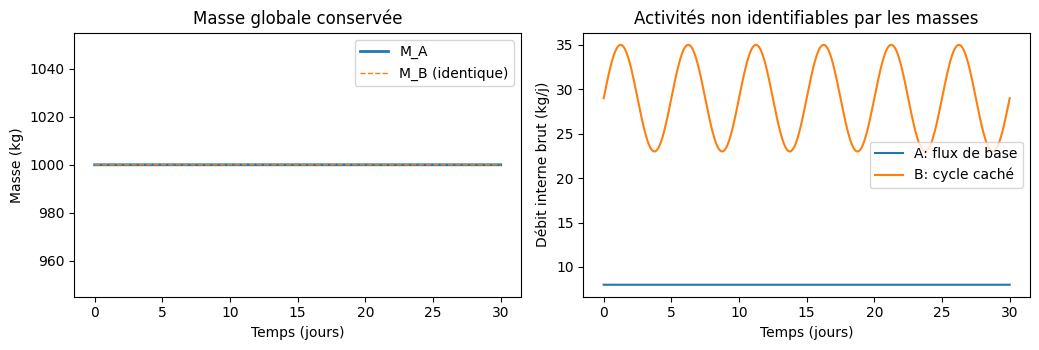

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(10.5,3.6))
ax[0].plot(T_DAY,MASS_A,label='M_A',linewidth=2)
ax[0].plot(T_DAY,MASS_B,'--',label='M_B (identique)',linewidth=1)
ax[0].set(xlabel='Temps (jours)',ylabel='Masse (kg)',title='Masse globale conservée');ax[0].legend()
ax[1].plot(T_DAY,ACTIVITY_A,label='A: flux de base')
ax[1].plot(T_DAY,ACTIVITY_B,label='B: cycle caché')
ax[1].set(xlabel='Temps (jours)',ylabel='Débit interne brut (kg/j)',title='Activités non identifiables par les masses');ax[1].legend()
fig.tight_layout();plt.show()

# Niveau 4 — Verdict scientifique

**PASS de l'audit local** :

1. $B$ a un noyau non trivial de dimension 1 ; les masses seules ne fixent pas la circulation interne.
2. L'action auxiliaire de continuité ne fournit aucune équation qui sélectionne $\boldsymbol J$.
3. Deux flux positifs différents donnent **exactement les mêmes masses à tous les instants**, mais des activités et consommations d'énergie différentes.
4. Une fréquence arbitraire peut être cachée dans la circulation interne : un rapport de fréquences entre cubes ne devient pas une prédiction si la fréquence est libre.

**BLOCKED pour la physique GVH** : l'action candidate archivée ne contient pas de matière à trois réservoirs, ni de courant de transport, ni de loi constitutive ni de couplage matière–$g,u,e$. Aucune EOM du secteur GVH ne sélectionne $A_C(t)$, $c(t)$, $\epsilon$, $P$, ou les taux de transition de ce jouet.

**Prochaine étape canonique prudente :** définir un secteur matière covariant explicite, sa conservation (incluant l'énergie), et une loi constitutive compatible avec les symétries, puis vérifier les EOM couplées et leurs limites physiques. Tout couplage ou taux nouveau doit être marqué `CANDIDATE_PRESCRIBED` tant qu'il n'est pas dérivé. Le prochain audit doit inclure une sortie indépendante tenue à l'écart de toute calibration.

In [8]:
LOCKS={
 'archived_S_cand_has_explicit_reservoirs': False,
 'GVH_transport_law_derived_from_action': False,
 'GVH_activity_eom_derived': False,
 'GVH_transport_frequency_derived': False,
 'GVH_absolute_SI_scale_derived': False,
 'new_GVH_physics_validated': False,
}
LOCAL_AUDIT_PASS=all([G_B_RANK_2,G_B_MASS_CONSERVE,G_CYCLE_NULLSPACE,G_RATE_UNIDENTIFIABLE,
 G_ACTIVITY_CHANGES,G_AUX_ACTION_CONTINUITY,G_AUX_ACTION_FLUX_EQUATION,
 G_FLUX_EOM_HAS_NO_FLUX,G_POSITIVE_FLUXES,G_POSITIVE_MASSES,
 G_MASS_HISTORY_EQUAL,G_TOTAL_MASS_CONSERVED,G_ACTIVITY_HISTORY_DIFFERENT,
 G_NUMERIC_FLUX_EOM,G_ENERGY_PASS,G_RESERVES_POSITIVE,G_ENERGY_QUADRATURE,
 G_HIDDEN_FREQUENCY_PASS,G_AGGREGATE_MASS_HAS_NO_HIDDEN_FREQUENCY,
 not any(LOCKS.values())])
assert LOCAL_AUDIT_PASS
RESULT={
 'notebook':NOTEBOOK,
 'classification':'COMPLEMENTARY_NONCANONICAL_FOUR_LEVEL_CLOSURE_AUDIT',
 'four_levels':{'GVH':'S_CAND_MATTER_TRANSPORT_SECTOR_NOT_SPECIFIED',
                'established_physics':'NETWORK_INCIDENCE_AND_ENERGY_ACCOUNTING',
                'minimal_numeric_test':'TWO_DISTINCT_FLUXES_SAME_MASS_HISTORY_PASS',
                'scientific_verdict':'LOCAL_NONIDENTIFIABILITY_PASS__GVH_ACTIVITY_EOM_BLOCKED'},
 'local_audit_pass':bool(LOCAL_AUDIT_PASS),
 'tests':{'incidence_rank_2':bool(G_B_RANK_2),'cycle_nullspace':bool(G_CYCLE_NULLSPACE),
          'conserved_total_mass':bool(G_TOTAL_MASS_CONSERVED),
          'same_entire_mass_history':bool(G_MASS_HISTORY_EQUAL),
          'different_internal_activities':bool(G_ACTIVITY_HISTORY_DIFFERENT),
          'auxiliary_continuity_flux_eom_does_not_fix_J':bool(G_FLUX_EOM_HAS_NO_FLUX),
          'toy_energy_bookkeeping':bool(G_ENERGY_PASS),
          'toy_finite_energy_reserve':bool(G_RESERVES_POSITIVE),
          'hidden_frequency_detected':bool(G_HIDDEN_FREQUENCY_PASS)},
 'numerical':{'M0_kg':M_INITIAL.tolist(),'Mfinal_kg':M_A[:,-1].tolist(),
              'final_total_mass_kg':float(MASS_A[-1]),
              'activity_A_kg_per_day':float(ACTIVITY_A[0]),
              'activity_B_min_kg_per_day':float(ACTIVITY_B.min()),
              'activity_B_max_kg_per_day':float(ACTIVITY_B.max()),
              'energy_A_consumed_J':float(Q_A[-1]),
              'energy_B_consumed_J':float(Q_B[-1]),
              'imposed_hidden_cycle_frequency_Hz':float(F_HIDDEN_HZ),
              'detected_hidden_cycle_frequency_Hz':float(F_NUM_HZ)},
 'parameters':{'fluxes_prescribed':True,'period_prescribed':True,'energy_cost_prescribed':True,
               'no_fitting_to_data':True,'units_are_SI_not_theory_derived':True},
 'upstream_sources':UPSTREAM_EXPECTED,
 'literature':[{'doi':'10.1007/s10955-006-9233-5','role':'network cycle currents'},
               {'doi':'10.1103/PhysRevE.91.012115','role':'scale dependent thermodynamics'},
               {'doi':'10.1103/PhysRevE.98.022102','role':'coarse-graining dissipation'}],
 'locks':LOCKS,
 'next_authorized':'EXPLICIT_COVARIANT_MATTER_ACTION_AND_CONSTITUTIVE_SOURCE_COUPLING_GATE'
}
DEST=ROOT/(NOTEBOOK+'_results.json')
DEST.write_text(json.dumps(RESULT,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
print('LOCAL_AUDIT_PASS =',LOCAL_AUDIT_PASS)
print('LEVEL4 =',RESULT['four_levels']['scientific_verdict'])
print('JSON artifact =',DEST)

LOCAL_AUDIT_PASS = True
LEVEL4 = LOCAL_NONIDENTIFIABILITY_PASS__GVH_ACTIVITY_EOM_BLOCKED
JSON artifact = /mnt/data/GVH_Hierarchical_Activity_Constitutive_Closure_Gate_FAST_results.json
